# Testing Model with Simulated Data
Evaluate Bernoulli model using simulated data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel
from gene_prevalence.simulations import build_observed_data_matrix, \
    build_presence_absence_matrix, build_three_part_pi_vector

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)


### Well-Specified Model
Validate that model behaves as expected when simulation matches model assumptions

In [2]:
# build simulated data that matches model assumptions

n_genomes = 1000
n_genes = 10000
genes_per_genome = 3000
n_core_genes = 800

# generate true pi values for all genes in the pangenome, with a three-part structure
pi_vector_true = build_three_part_pi_vector(
    pangenome_size=n_genes, 
    genes_per_genome=genes_per_genome, 
    n_core_genes=n_core_genes, 
    non_core_span=(0.05, 1.0)
    )

# build a presence-absence matrix based on the true pi values
presence_absence_matrix = build_presence_absence_matrix(
    pi_vector=pi_vector_true, 
    n_genomes=n_genomes, 
    n_genes=n_genes,
    rng=rng
    )

# generate completeness values for each genome, with a subset being complete
completeness_vector = pd.Series(
    np.clip(rng.uniform(low=0.05, high=1.1, size=n_genomes), 0, 1), 
    index=presence_absence_matrix.columns
    )

# build an observed data matrix by simulating the observation process with no 
# gene-specific biases and not enforcing completeness (i.e. simulating each gene 
# observation as an independent Bernoulli trial)

observed_data_matrix, observation_mask = build_observed_data_matrix(
    presence_absence_matrix=presence_absence_matrix,
    completeness_levels=completeness_vector,
    rng=rng, 
    return_observation_mask=True
    )

observed_data_matrix


,sim_genome_0,sim_genome_1,sim_genome_2,sim_genome_3,sim_genome_4,sim_genome_5,sim_genome_6,sim_genome_7,sim_genome_8,sim_genome_9,...,sim_genome_990,sim_genome_991,sim_genome_992,sim_genome_993,sim_genome_994,sim_genome_995,sim_genome_996,sim_genome_997,sim_genome_998,sim_genome_999
sim_gene_0,1,1,0,1,0,1,1,1,0,0,...,1,1,1,1,1,1,1,0,0,0
sim_gene_1,1,1,0,1,0,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
sim_gene_2,1,1,1,1,0,1,0,0,1,0,...,0,1,1,1,0,0,1,1,0,0
sim_gene_3,1,1,0,1,0,0,0,1,1,0,...,1,1,1,1,1,0,1,0,0,0
sim_gene_4,1,0,0,1,1,0,0,1,1,0,...,1,1,1,1,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sim_gene_9995,1,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
sim_gene_9996,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
sim_gene_9997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
sim_gene_9998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# fit the Bernoulli prevalence model to the simulated data

# fit model to simulated dataset
model = BernoulliPrevalenceModel(
    data=observed_data_matrix,
    lambdas=completeness_vector,
    clip_max=1.0,  # prevalence cannot exceed 1.0
)
pi_hat = model.estimate_prevalence()
ci_lower, ci_upper = model.confidence_interval(alpha=0.05) # 95% confidence intervals

# pull results together into a dataframe
estimate_df = pd.DataFrame(
    {
        "pi_true": pi_vector_true,
        "pi_hat": pi_hat, 
        "ci_95_upper": ci_upper,
        "ci_95_lower": ci_lower,
    }
)

# estimate confidence intervals at various significance levels
alpha_values = np.linspace(0.01, 0.99, 99)
results = []
for a in alpha_values:
    ci_lower, ci_upper = model.confidence_interval(alpha=a)

    true_in_ci = (
        (estimate_df["pi_true"] >= ci_lower.loc[estimate_df.index]) &
        (estimate_df["pi_true"] <= ci_upper.loc[estimate_df.index])
    )

    results.append({
        "significance_level": a,
        "confidence_level": 1 - a,
        "pi_true_within_ci": true_in_ci.mean(),
    })

ci_results_df = pd.DataFrame(results)
ci_results_df.loc[np.r_[1:10, 40:50], :]


,significance_level,confidence_level,pi_true_within_ci
1,0.02,0.98,0.9994
2,0.03,0.97,0.9964
3,0.04,0.96,0.9871
4,0.05,0.95,0.9724
5,0.06,0.94,0.9569
6,0.07,0.93,0.9386
7,0.08,0.92,0.9196
8,0.09,0.91,0.9037
9,0.10,0.90,0.8867
40,0.41,0.59,0.5768


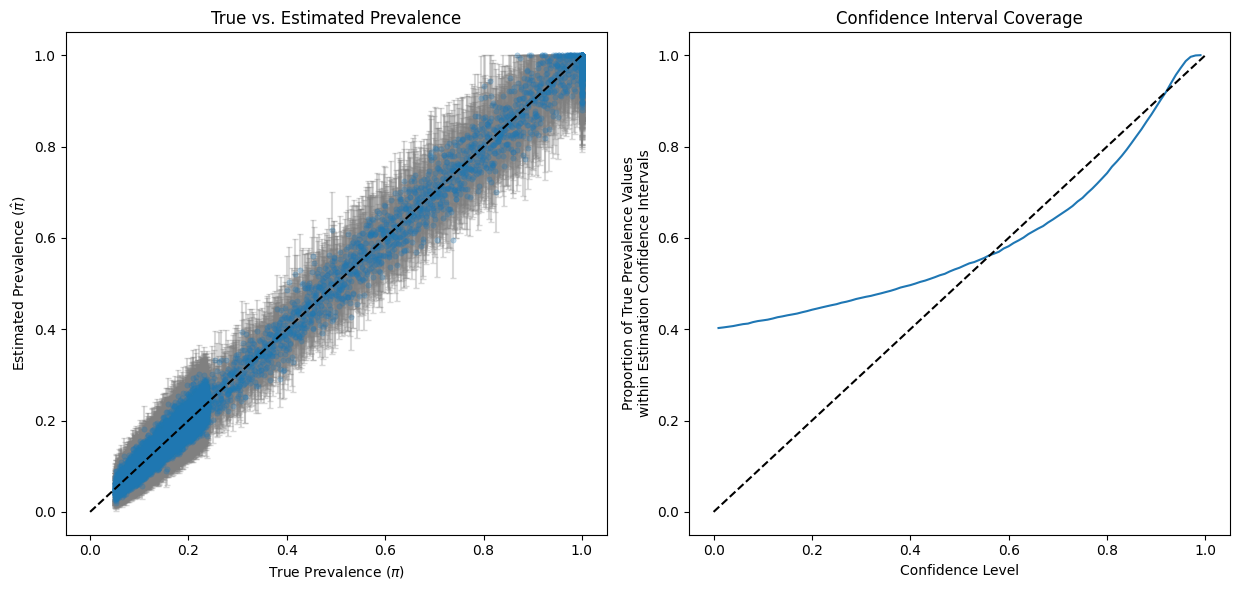

In [4]:
# plot results in two panels: 
#     (1) true vs. estimated prevalence with confidence intervals
#     (2) coverage of confidence intervals across significance levels

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))

# panel 1: true vs. estimated prevalence with confidence intervals
sns.scatterplot(
    data=estimate_df,
    x="pi_true",
    y="pi_hat",
    ax=axes[0], 
    alpha=0.3, 
    zorder=2, 
    edgecolor=None, 
    s=15
)
# add error bars for confidence intervals
axes[0].errorbar(
    x=estimate_df["pi_true"],
    y=estimate_df["pi_hat"],
    yerr=[estimate_df["pi_hat"] - estimate_df["ci_95_lower"], estimate_df["ci_95_upper"] - estimate_df["pi_hat"]],
    fmt="none",
    ecolor="grey", 
    capsize=2,
    alpha=0.3, 
    zorder=1
)
axes[0].plot([0, 1], [0, 1], color="black", linestyle="--")  # add y=x reference line
axes[0].set_xlim(-0.05, 1.05)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_title("True vs. Estimated Prevalence")
axes[0].set_xlabel(r"True Prevalence ($\pi$)")
axes[0].set_ylabel(r"Estimated Prevalence ($\hat{\pi}$)")

# panel 2: coverage of confidence intervals across significance levels
sns.lineplot(
    data=ci_results_df,
    x="confidence_level",
    y="pi_true_within_ci",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], color="black", linestyle="--")  # add y=x reference line
axes[1].set_xlim(-0.05, 1.05)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Confidence Interval Coverage")
axes[1].set_xlabel("Confidence Level")
axes[1].set_ylabel("Proportion of True Prevalence Values\nwithin Estimation Confidence Intervals")

# show the plot
plt.tight_layout()
plt.show()

In [5]:
# fit the Bernoulli prevalence model to the complete and incomplete genomes independently

# separate out complete and incomplete genomes
sim_complete_df = observed_data_matrix.loc[:, completeness_vector == 1]
sim_incomplete_df = observed_data_matrix.loc[:, completeness_vector < 1]

# complete genomes
complete_model = BernoulliPrevalenceModel(
    data=sim_complete_df,
    lambdas=completeness_vector[completeness_vector == 1],
    clip_max=1.0,  # prevalence cannot exceed 1.0
)
pi_hat_complete = complete_model.estimate_prevalence()
ci_lower_complete, ci_upper_complete = complete_model.confidence_interval(
    alpha=0.05)

# incomplete genomes
incomplete_model = BernoulliPrevalenceModel(
    data=sim_incomplete_df,
    lambdas=completeness_vector[completeness_vector < 1],
    clip_max=1.0,  # prevalence cannot exceed 1.0
)
pi_hat_incomplete = incomplete_model.estimate_prevalence()
ci_lower_incomplete, ci_upper_incomplete = incomplete_model.confidence_interval(
    alpha=0.05)

# add results to estimate dataframe
estimate_df["pi_hat_complete"] = pi_hat_complete
estimate_df["ci_upper_complete"] = ci_upper_complete
estimate_df["ci_lower_complete"] = ci_lower_complete
estimate_df["pi_hat_incomplete"] = pi_hat_incomplete
estimate_df["ci_upper_incomplete"] = ci_upper_incomplete
estimate_df["ci_lower_incomplete"] = ci_lower_incomplete

# calculate proportions of points where true prevalence is within each CI
# and where each estimate is within the other's CI
true_in_complete = (
    (estimate_df["pi_true"] >= estimate_df["ci_lower_complete"]) &
    (estimate_df["pi_true"] <= estimate_df["ci_upper_complete"])
)
true_in_incomplete = (
    (estimate_df["pi_true"] >= estimate_df["ci_lower_incomplete"]) &
    (estimate_df["pi_true"] <= estimate_df["ci_upper_incomplete"])
)
within_ci_complete = (
    (estimate_df["pi_hat_incomplete"] >= estimate_df["ci_lower_complete"]) &
    (estimate_df["pi_hat_incomplete"] <= estimate_df["ci_upper_complete"])
)
within_ci_incomplete = (
    (estimate_df["pi_hat_complete"] >= estimate_df["ci_lower_incomplete"]) &
    (estimate_df["pi_hat_complete"] <= estimate_df["ci_upper_incomplete"])
)
print(f"Proportion of points where true prevalence is within complete CI: {true_in_complete.mean():.2f}")
print(f"Proportion of points where true prevalence is within incomplete CI: {true_in_incomplete.mean():.2f}")
print(f"Proportion of points where incomplete estimate is within complete CI: {within_ci_complete.mean():.2f}")
print(f"Proportion of points where complete estimate is within incomplete CI: {within_ci_incomplete.mean():.2f}")
print(f"Proportion of points where at least one estimate is within the other's CI: {(within_ci_complete | within_ci_incomplete).mean():.2f}")
print(f"Proportion of points where both estimates are within each other's CI: {(within_ci_complete & within_ci_incomplete).mean():.2f}")

estimate_df

Proportion of points where true prevalence is within complete CI: 0.96
Proportion of points where true prevalence is within incomplete CI: 0.97
Proportion of points where incomplete estimate is within complete CI: 0.89
Proportion of points where complete estimate is within incomplete CI: 0.79
Proportion of points where at least one estimate is within the other's CI: 0.94
Proportion of points where both estimates are within each other's CI: 0.74


,pi_true,pi_hat,ci_95_upper,ci_95_lower,pi_hat_complete,ci_upper_complete,ci_lower_complete,pi_hat_incomplete,ci_upper_incomplete,ci_lower_incomplete
sim_gene_0,1.000000,0.937007,1.000000,0.842891,1.000000,1.000000,1.000000,0.930240,1.000000,0.826391
sim_gene_1,1.000000,1.000000,1.000000,0.947099,1.000000,1.000000,1.000000,1.000000,1.000000,0.941177
sim_gene_2,1.000000,1.000000,1.000000,0.976773,1.000000,1.000000,1.000000,1.000000,1.000000,0.973882
sim_gene_3,1.000000,0.963530,1.000000,0.868764,1.000000,1.000000,1.000000,0.959613,1.000000,0.854880
sim_gene_4,1.000000,1.000000,1.000000,0.948842,1.000000,1.000000,1.000000,1.000000,1.000000,0.943098
...,...,...,...,...,...,...,...,...,...,...
sim_gene_9995,0.050103,0.027075,0.046546,0.007603,0.051546,0.101747,0.001346,0.024446,0.044596,0.004296
sim_gene_9996,0.050077,0.047270,0.072904,0.021635,0.041237,0.086381,0.000000,0.047918,0.076018,0.019817
sim_gene_9997,0.050051,0.045526,0.070691,0.020360,0.051546,0.101747,0.001346,0.044879,0.072087,0.017670
sim_gene_9998,0.050026,0.032808,0.054220,0.011396,0.061856,0.116548,0.007164,0.029687,0.051873,0.007502


In [6]:
# compile results at different significance levels for confidence intervals

alpha_values = np.linspace(0.01, 0.99, 99)

# save results for each alpha value in a list of dictionaries
results = []
for a in alpha_values:
    ci_lower_complete, ci_upper_complete = complete_model.confidence_interval(alpha=a)
    ci_lower_incomplete, ci_upper_incomplete = incomplete_model.confidence_interval(alpha=a)
    true_in_complete = (
        (estimate_df["pi_true"] >= ci_lower_complete.loc[estimate_df.index]) &
        (estimate_df["pi_true"] <= ci_upper_complete.loc[estimate_df.index])
    )
    true_in_incomplete = (
        (estimate_df["pi_true"] >= ci_lower_incomplete.loc[estimate_df.index]) &
        (estimate_df["pi_true"] <= ci_upper_incomplete.loc[estimate_df.index])
    )
    # identify incomplete estimates that fall within the complete confidence intervals
    within_ci_complete = (
        (estimate_df["pi_hat_incomplete"] >= ci_lower_complete.loc[estimate_df.index]) &
        (estimate_df["pi_hat_incomplete"] <= ci_upper_complete.loc[estimate_df.index])
    )
    # identify complete estimates that fall within the incomplete confidence intervals
    within_ci_incomplete = (
        (estimate_df["pi_hat_complete"] >= ci_lower_incomplete.loc[estimate_df.index]) &
        (estimate_df["pi_hat_complete"] <= ci_upper_incomplete.loc[estimate_df.index])
    )
    results.append({
        "significance_level": a,
        "confidence_level": 1 - a,
        "pi_true_within_ci_comp": true_in_complete.mean(),
        "pi_true_within_ci_inc": true_in_incomplete.mean(),
        "pi_inc_within_ci_comp": within_ci_complete.mean(),
        "pi_comp_within_ci_inc": within_ci_incomplete.mean(),
        "within_either_ci": (within_ci_complete | within_ci_incomplete).mean(),
        "within_both_ci": (within_ci_complete & within_ci_incomplete).mean(),
    })

ci_results_df = pd.DataFrame(results)
ci_results_df

,significance_level,confidence_level,pi_true_within_ci_comp,pi_true_within_ci_inc,pi_inc_within_ci_comp,pi_comp_within_ci_inc,within_either_ci,within_both_ci
0,0.01,0.99,0.9963,1.0000,0.9565,0.9911,0.9997,0.9479
1,0.02,0.98,0.9928,0.9993,0.9477,0.9479,0.9920,0.9036
2,0.03,0.97,0.9854,0.9965,0.9310,0.8883,0.9769,0.8424
3,0.04,0.96,0.9763,0.9872,0.9110,0.8346,0.9573,0.7883
4,0.05,0.95,0.9617,0.9726,0.8900,0.7888,0.9369,0.7419
...,...,...,...,...,...,...,...,...
94,0.95,0.05,0.4362,0.4104,0.3369,0.2622,0.3585,0.2406
95,0.96,0.04,0.4343,0.4087,0.3357,0.2617,0.3573,0.2401
96,0.97,0.03,0.4321,0.4069,0.3332,0.2602,0.3548,0.2386
97,0.98,0.02,0.4307,0.4045,0.3316,0.2593,0.3530,0.2379


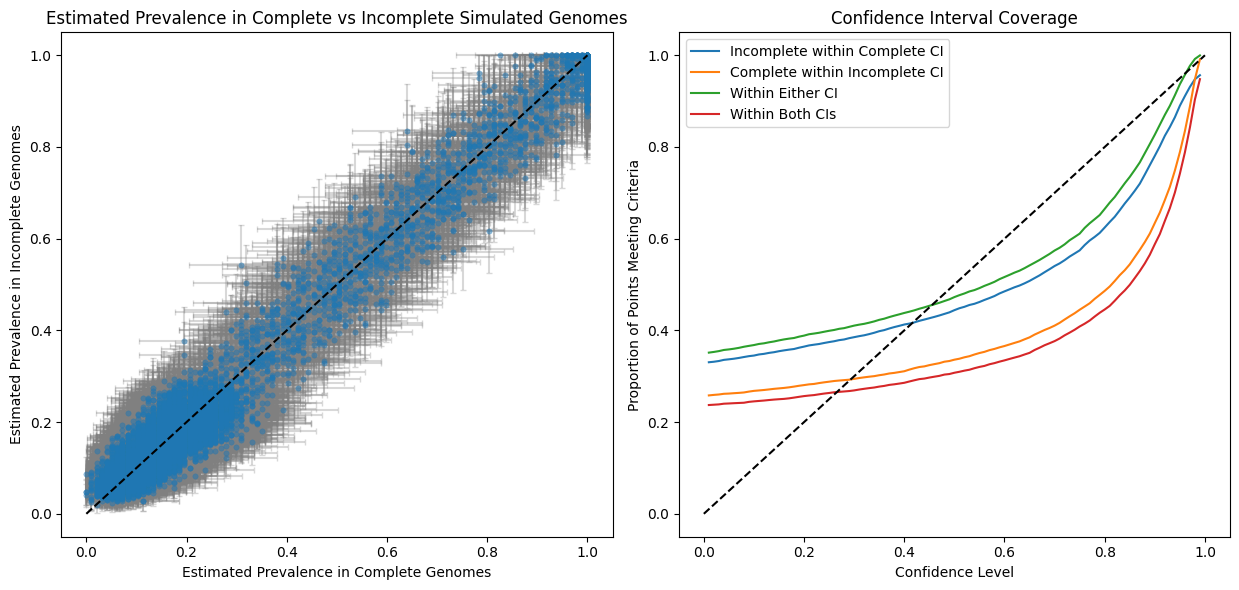

In [11]:
# plot results in two panels: 
#     (1) estimated prevalence in complete vs. incomplete genomes with confidence intervals
#     (2) coverage of confidence intervals across significance levels

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))

# panel 1: estimated prevalence in complete vs. incomplete genomes with confidence intervals
sns.scatterplot(
    data=estimate_df,
    x="pi_hat_complete",
    y="pi_hat_incomplete",
    # hue="mean_gene_copy",
    # style="mean_gene_copy",
    s=15,
    alpha=0.5,
    edgecolor=None,
    zorder=2,
    ax=axes[0]
) 
# add error bars 
axes[0].errorbar(
    x=estimate_df["pi_hat_complete"],
    y=estimate_df["pi_hat_incomplete"],
    xerr=[estimate_df["pi_hat_complete"] - estimate_df["ci_lower_complete"], 
          estimate_df["ci_upper_complete"] - estimate_df["pi_hat_complete"]],
    yerr=[estimate_df["pi_hat_incomplete"] - estimate_df["ci_lower_incomplete"], 
          estimate_df["ci_upper_incomplete"] - estimate_df["pi_hat_incomplete"]],
    fmt="none",
    ecolor="gray",
    capsize=2,
    alpha=0.3,
    zorder=1,  # put error bars behind points
)
# add a dashed diagonal line for reference
axes[0].plot([0, 1], [0, 1], "--", color="black", zorder=3)
axes[0].set_xlim(-0.05, 1.05)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_title("Estimated Prevalence in Complete vs Incomplete Simulated Genomes")
axes[0].set_xlabel("Estimated Prevalence in Complete Genomes")
axes[0].set_ylabel("Estimated Prevalence in Incomplete Genomes")

# panel 2: coverage of confidence intervals across significance levels
sns.lineplot(
    data=ci_results_df,
    x="confidence_level",
    y="pi_inc_within_ci_comp",
    ax=axes[1],
    label="Incomplete within Complete CI"
)
sns.lineplot(
    data=ci_results_df,
    x="confidence_level",
    y="pi_comp_within_ci_inc",
    ax=axes[1],
    label="Complete within Incomplete CI"
)
sns.lineplot(
    data=ci_results_df,
    x="confidence_level",
    y="within_either_ci",
    ax=axes[1],
    label="Within Either CI"
)
sns.lineplot(
    data=ci_results_df,
    x="confidence_level",
    y="within_both_ci",
    ax=axes[1],
    label="Within Both CIs"
)
axes[1].plot([0, 1], [0, 1], color="black", linestyle="--")  # add y=x reference line
axes[1].set_xlim(-0.05, 1.05)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Confidence Interval Coverage")
axes[1].set_xlabel("Confidence Level")
axes[1].set_ylabel("Proportion of Points Meeting Criteria")

# show the plot
plt.tight_layout()
plt.show()